In [41]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import re
import cv2

ROOT = Path("/Users/marcellobullo/research/FINAL/github/djscc-playground")
RESULTS_DIR = ROOT / "results"
EXP_DIR = RESULTS_DIR / "djscc-psnr-vs-snr"

SNR_DIR_RE = re.compile(r"snr_?(-?\d+)\s*dB", re.IGNORECASE)
RESULT_IDX_RE = re.compile(r"_(\d+)\.png$", re.IGNORECASE)

WIDTH = 768
HEIGHT = 512

match = "index" 

In [42]:
def load_rgb(path: Path, width: int, height: int) -> np.ndarray:
    """Load an image as an HxWx3 uint8 array (drops alpha if present)."""
    #return np.asarray(Image.open(path).convert("RGB"))
    image_bgr = np.array(Image.open(path))
    return cv2.resize(image_bgr, (width, height))


def load_originals(originals_dir: Path, width: int, height: int) -> dict[str, np.ndarray]:
    originals = {}
    for p in sorted(originals_dir.glob("*.png")):
        originals[p.stem] = load_rgb(p, width, height)
    if not originals:
        raise SystemExit(f"No PNG originals found in {originals_dir}")
    return originals

def psnr(a: np.ndarray, b: np.ndarray) -> float:
    """Standard RGB PSNR in dB (MAX=255). Returns inf for identical images."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10.0 * np.log10((255.0 ** 2) / mse)

def _unpack(summary):
    s0 = np.array([s[0] for s in summary])
    s1 = np.array([s[1] for s in summary])
    s2 = np.array([s[2] for s in summary])
    return s0, s1, s2

Loaded 24 originals from /Users/marcellobullo/Downloads/kodak_dataset


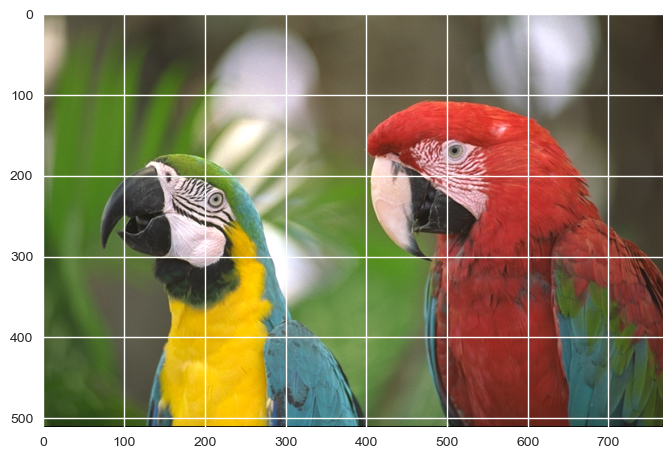

In [43]:
orig_path = "/Users/marcellobullo/Downloads/kodak_dataset"

originals = load_originals(Path(orig_path), WIDTH, HEIGHT)
print(f"Loaded {len(originals)} originals from {Path(orig_path)}")

img_idx = 23
img = originals[f"kodim{img_idx:02}"]
plt.imshow(img)
plt.show()

### Qualitatively Plots

In [44]:
snr_dirs = []
for d in sorted(EXP_DIR.iterdir()):
    if not d.is_dir():
        continue
    m = SNR_DIR_RE.search(d.name)
    if m:
        snr_dirs.append((int(m.group(1)), d))
snr_dirs.sort(key=lambda t: t[0])
if not snr_dirs:
    raise SystemExit(f"No snr_*dB sub-folders found in {EXP_DIR}")

#snr_dirs

rows = []          # per-image records for the CSV
summary = [] 

for snr, d in snr_dirs:
    vals = []
    #print(f"\nSNR {snr:>3} dB  ({d.name})")
    for img_path in sorted(d.glob("*.png")):
        #print("image path: ", img_path)
        recon = load_rgb(img_path, WIDTH, HEIGHT)
        img_index = int(img_path.with_suffix("").name.split("_")[1])
        original_name = f"kodim{img_index:02d}"
        original_img = originals.get(original_name)
        PSNR = psnr(recon, original_img)

        vals.append(PSNR)
        rows.append({"snr_db": snr, "result": img_path.name,
                        "matched_original": original_name,
                        "psnr_db": round(PSNR, 4)})
        #print(f"  {img_path.name:<18} -> {original_name}  PSNR {PSNR:6.2f} dB")
    if vals:
        arr = np.asarray(vals)
        summary.append((snr, float(arr.mean()), float(arr.std()), len(arr)))

# summary

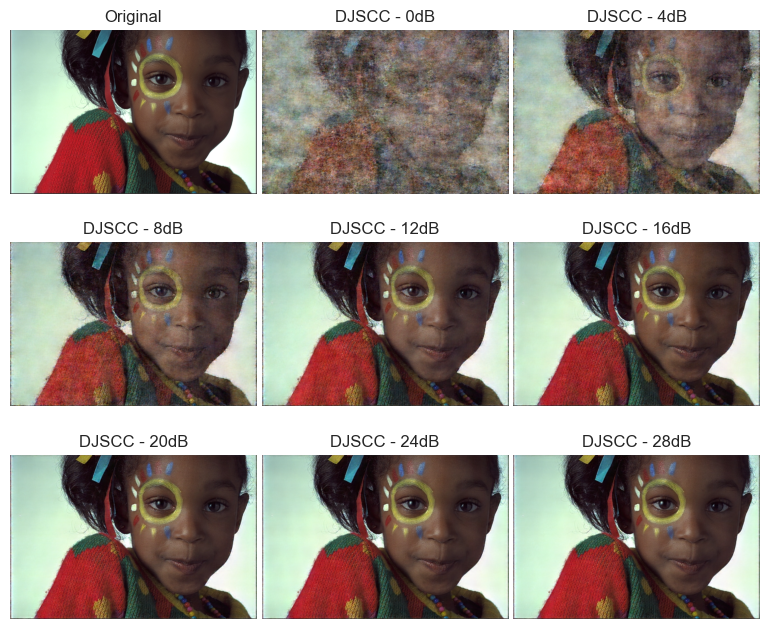

In [45]:
import math
import matplotlib.pyplot as plt

img_idx = 15
img_orig = originals[f"kodim{img_idx:02}"]

# 1. Determine total images and calculate grid dimensions
total_images = 1 + len(snr_dirs)
cols = 3  
rows = math.ceil(total_images / cols)

# 2. Create the grid (slightly smaller base size per image)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))

if total_images > 1:
    axes = axes.flatten()
else:
    axes = [axes]

# 3. Plot the original image
axes[0].imshow(img_orig)
axes[0].set_title("Original")
axes[0].axis('off')

# 4. Loop through snr_dirs and plot the rest
for i, (snr, d) in enumerate(snr_dirs):
    rec_images = sorted(d.glob("*.png"))
    img_rec = load_rgb(rec_images[img_idx-1], WIDTH, HEIGHT) 
    
    ax_idx = i + 1
    axes[ax_idx].imshow(img_rec)
    axes[ax_idx].set_title(f"DJSCC - {snr}dB")
    axes[ax_idx].axis('off')

# 5. Hide any empty subplots
for j in range(total_images, len(axes)):
    axes[j].axis('off')

# 6. Crush the whitespace
# wspace controls horizontal gaps, hspace controls vertical gaps
plt.subplots_adjust(wspace=0.02, hspace=0.0, left=0, right=1, bottom=0, top=0.85)
plt.savefig("/Users/marcellobullo/Downloads/kodim23_djscc_snr_comparison.png", dpi=600, bbox_inches='tight')

plt.show()

### Quantitatively Plots: PSNR and SSIM vs SNR over Kodak dataset

[]

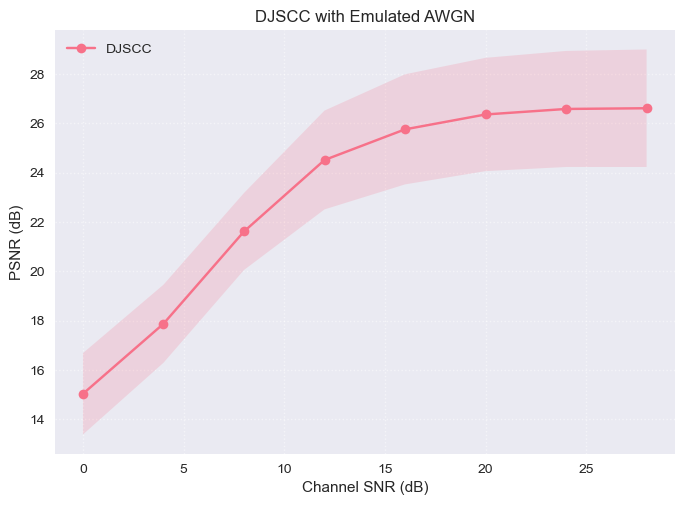

In [46]:
snrs = np.array([s[0] for s in summary])
means = np.array([s[1] for s in summary])
stds = np.array([s[2] for s in summary])

plt.plot(snrs, means, "o-", label="DJSCC")
plt.fill_between(snrs, means+stds, means-stds, alpha=0.2)

plt.grid(linestyle=":", alpha=0.5)

plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("DJSCC with Emulated AWGN")
plt.legend()
plt.plot()

### Structural Similarity Index Measure (SSIM) 

In [47]:
import torch
from kaira.metrics.image import SSIM

SETTINGS = {
    "DJSCC": EXP_DIR,
}

device = ("mps" if torch.backends.mps.is_available()
         else "cuda" if torch.cuda.is_available() else "cpu")

kaira_ssim_model = SSIM(data_range=1.0).to(device).eval()

def img2tensor(img_uint8):
    """HxWx3 uint8 RGB -> 1x3xHxW float in [0,1] for the Kaira metrics."""
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1)
    return t.unsqueeze(0).float().div(255.0)


def get_folders(base):
    return sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d)
                   for d in base.iterdir()
                   if d.is_dir() and SNR_DIR_RE.search(d.name)),
                  key=lambda t: t[0])


@torch.no_grad()
def summarize_metric(base, metric):
    """Mean/std of a Kaira image metric vs SNR over the snr_*dB subfolders of `base`."""
    out = []
    for snr, d in get_folders(base):
        metric_values = []
        for img_path in sorted(d.glob("*.png")):
            idx = int(img_path.with_suffix("").name.split("_")[1])
            o = originals.get(f"kodim{idx:02d}")
            if o is None:                      # stray index w/o matching original
                continue
            x = img2tensor(load_rgb(img_path, WIDTH, HEIGHT)).to(device)
            y = img2tensor(o).to(device)
            metric_value = float(metric(x, y).mean().cpu())
            metric_values.append(metric_value)
        metric_values = np.asarray(metric_values)
        out.append((snr, metric_values.mean(), metric_values.std(), len(metric_values)))
    return out


# Compute SSIM
ssim_dict_values = {name: summarize_metric(base, kaira_ssim_model) for name, base in SETTINGS.items()}


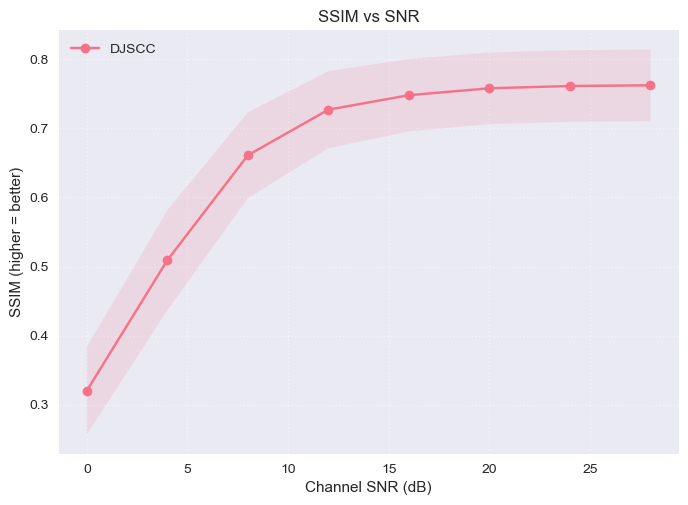

In [29]:
for name, summary in ssim_dict_values.items():
    snrs, ssim_mean, ssim_std = _unpack(summary)
    plt.plot(snrs, ssim_mean, "-o", label=name)
    plt.fill_between(snrs, ssim_mean + ssim_std, ssim_mean - ssim_std, alpha=0.15)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("SSIM (higher = better)")
plt.title("SSIM vs SNR")
plt.legend()
plt.show()

## Alignment

In [48]:
ALIGN_DIR = RESULTS_DIR / "djscc-alignment" / "aligner-conv-bourtsoulatze2convnext_spatialcsi-cr6-ofdm"


def summarize_condition(cond_dir: Path):
    """Mean/std PSNR per SNR over the snr_*dB subfolders of `cond_dir`.

    Same logic as the AWGN sweep above: match each reconstruction to its
    original by the trailing index in the filename (snrX_NNN.png -> kodimNN).
    Stray indices without a matching original (e.g. a stray _025) are skipped.
    """
    snr_dirs = []
    for d in sorted(cond_dir.iterdir()):
        if not d.is_dir():
            continue
        m = SNR_DIR_RE.search(d.name)
        if m:
            snr_dirs.append((int(m.group(1)), d))
    snr_dirs.sort(key=lambda t: t[0])

    summary = []
    for snr, d in snr_dirs:
        vals = []
        for img_path in sorted(d.glob("*.png")):
            img_index = int(img_path.with_suffix("").name.split("_")[1])
            original_img = originals.get(f"kodim{img_index:02d}")
            if original_img is None:        # stray index w/o matching original
                continue
            recon = load_rgb(img_path, WIDTH, HEIGHT)
            vals.append(psnr(recon, original_img))
        if vals:
            arr = np.asarray(vals)
            summary.append((snr, float(arr.mean()), float(arr.std()), len(arr)))
    return summary


aligned_summary = summarize_condition(ALIGN_DIR / "aligned")
misaligned_summary = summarize_condition(ALIGN_DIR / "misaligned")

print("aligned:   ", aligned_summary)
print("misaligned:", misaligned_summary)

aligned:    [(0, 15.96537464395702, 1.5912749219425, 24), (4, 19.35142445519168, 1.738054275332462, 24), (8, 21.52414925190057, 1.5983787031787267, 24), (12, 21.80693225768923, 1.5549920237843875, 24), (16, 21.668157596255725, 1.5474333288713424, 24), (20, 21.637970396120267, 1.526648898446798, 24), (24, 21.65600734413461, 1.5133338290378366, 24), (28, 21.60251175088359, 1.5355154134147793, 24)]
misaligned: [(0, 12.44321835999717, 2.0935962665476033, 24), (4, 11.36857303118318, 2.21021098818673, 24), (8, 11.465442454698026, 2.308759748144883, 24), (12, 12.037221581790225, 2.3136572150765025, 24), (16, 12.286673497321393, 2.26072233901162, 24), (20, 12.408741392691818, 2.251765691318827, 24), (24, 12.451742273701756, 2.2414237664197487, 24), (28, 12.457903152229534, 2.243550107648322, 24)]


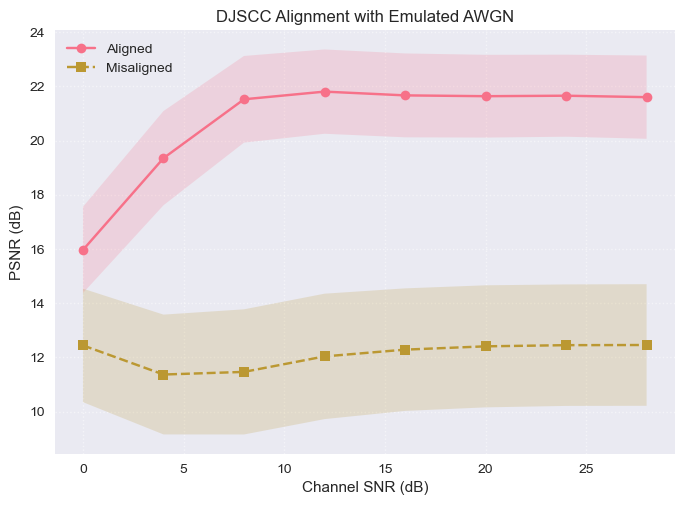

In [49]:
def _unpack(summary):
    snrs = np.array([s[0] for s in summary])
    means = np.array([s[1] for s in summary])
    stds = np.array([s[2] for s in summary])
    return snrs, means, stds


a_snr, a_mean, a_std = _unpack(aligned_summary)
m_snr, m_mean, m_std = _unpack(misaligned_summary)

plt.plot(a_snr, a_mean, "o-", label="Aligned")
plt.fill_between(a_snr, a_mean + a_std, a_mean - a_std, alpha=0.2)

plt.plot(m_snr, m_mean, "s--", label="Misaligned")
plt.fill_between(m_snr, m_mean + m_std, m_mean - m_std, alpha=0.2)

plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("DJSCC Alignment with Emulated AWGN")
plt.legend()

plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_psnr_aligned_vs_misaligned.png", dpi=800, bbox_inches='tight')
plt.show()

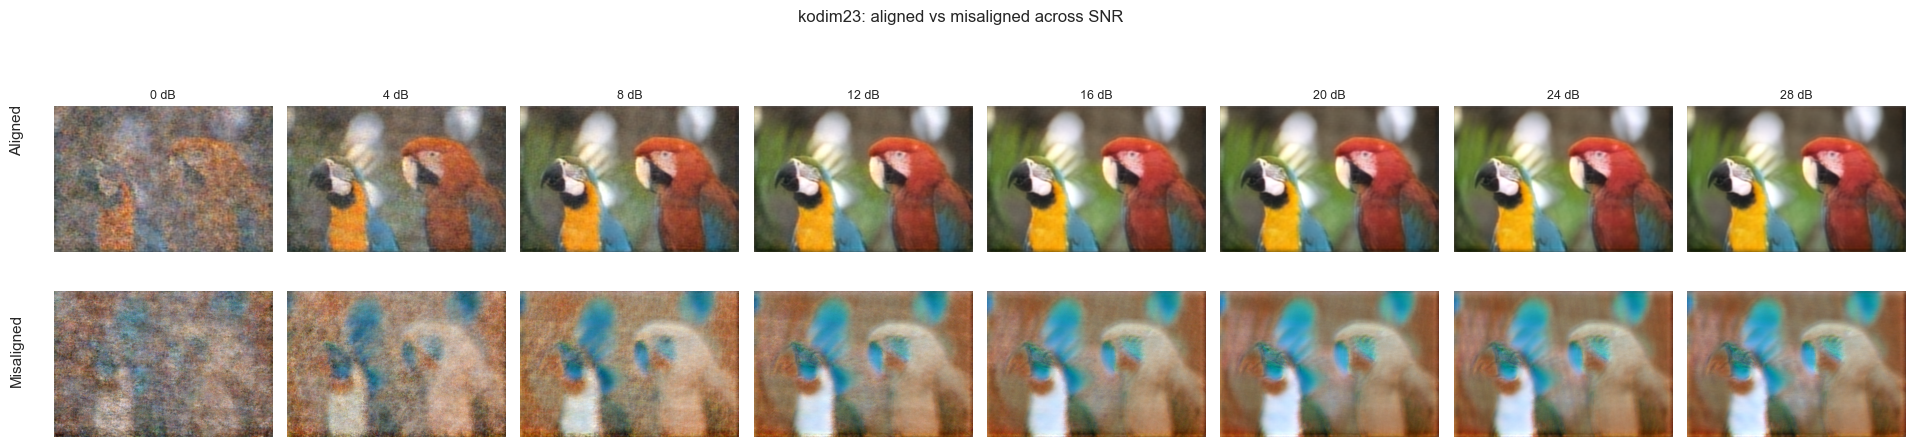

In [50]:
# Visual sanity check: aligned vs misaligned reconstructions across SNR.
# The misaligned row should stay garbage at every SNR (incl. the highest) ---
# that's the qualitative signature of the flat PSNR curve above.
img_idx = 23   # kodimNN to inspect


def _cond_snr_dirs(cond):
    cd = ALIGN_DIR / cond
    sd = [(int(SNR_DIR_RE.search(d.name).group(1)), d)
          for d in cd.iterdir() if d.is_dir() and SNR_DIR_RE.search(d.name)]
    return sorted(sd, key=lambda t: t[0])


def _recon(cond, snr, d, idx):
    f = d / f"snr{snr}_{idx:03d}.png"
    return load_rgb(f, WIDTH, HEIGHT) if f.exists() else None


snrs_a = _cond_snr_dirs("aligned")
ncol = len(snrs_a)
fig, axs = plt.subplots(2, ncol, figsize=(2.4 * ncol, 5))
for j, (snr, d) in enumerate(snrs_a):
    im = _recon("aligned", snr, d, img_idx)
    if im is not None:
        axs[0, j].imshow(im)
    axs[0, j].set_title(f"{snr} dB", fontsize=9)
    axs[0, j].axis("off")
for j, (snr, d) in enumerate(_cond_snr_dirs("misaligned")):
    im = _recon("misaligned", snr, d, img_idx)
    if im is not None:
        axs[1, j].imshow(im)
    axs[1, j].axis("off")

fig.text(0.005, 0.74, "Aligned", rotation=90, va="center", fontsize=11)
fig.text(0.005, 0.30, "Misaligned", rotation=90, va="center", fontsize=11)
fig.suptitle(f"kodim{img_idx:02d}: aligned vs misaligned across SNR")
plt.tight_layout(rect=[0.02, 0, 1, 0.97])
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_aligned_vs_misaligned.png", dpi=800, bbox_inches='tight')
plt.show()

### Luma / chroma decomposition

Plain RGB-PSNR mixes structure and color into one number. Splitting into YCrCb
separates *structure* (luma **Y**) from *color* (chroma **Cr/Cb**). For the
misaligned model these move in **opposite** directions with SNR --- luma improves
(structure returns) while chroma degrades (it commits to confident wrong colors)
--- so they cancel in RGB-PSNR and the curve looks flat.

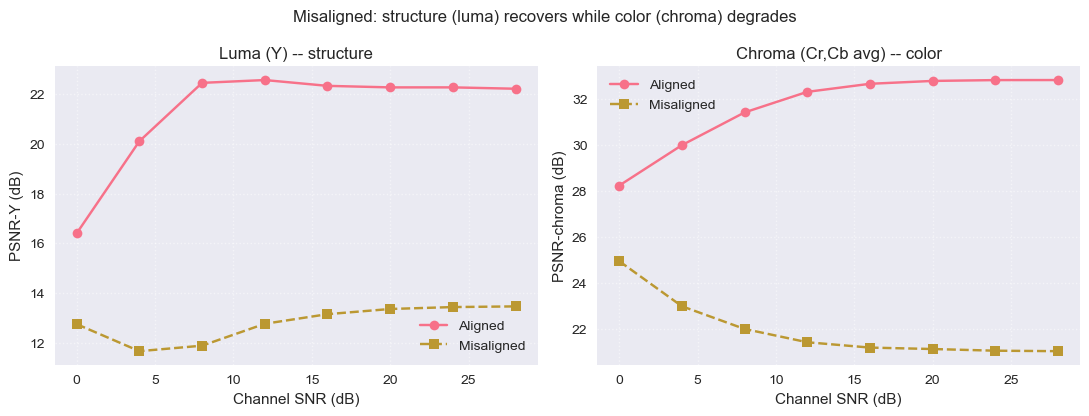

In [51]:
def summarize_ycc(cond):
    """Per-channel PSNR (Y, Cr, Cb) vs SNR for one condition (aligned/misaligned)."""
    cd = ALIGN_DIR / cond
    snr_dirs = sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d)
                       for d in cd.iterdir()
                       if d.is_dir() and SNR_DIR_RE.search(d.name)),
                      key=lambda t: t[0])
    rows = []
    for snr, d in snr_dirs:
        ch = {0: [], 1: [], 2: []}
        for img_path in sorted(d.glob("*.png")):
            idx = int(img_path.with_suffix("").name.split("_")[1])
            o = originals.get(f"kodim{idx:02d}")
            if o is None:
                continue
            ref = cv2.cvtColor(o, cv2.COLOR_RGB2YCrCb).astype(np.float64)
            rec = cv2.cvtColor(load_rgb(img_path, WIDTH, HEIGHT),
                               cv2.COLOR_RGB2YCrCb).astype(np.float64)
            for c in (0, 1, 2):
                mse = np.mean((rec[..., c] - ref[..., c]) ** 2)
                ch[c].append(np.inf if mse == 0 else 10.0 * np.log10(255.0 ** 2 / mse))
        rows.append((snr, np.mean(ch[0]), np.mean(ch[1]), np.mean(ch[2])))
    a = np.array(rows)
    return a[:, 0], a[:, 1], a[:, 2], a[:, 3]   # snr, Y, Cr, Cb


a_snr, aY, aCr, aCb = summarize_ycc("aligned")
m_snr, mY, mCr, mCb = summarize_ycc("misaligned")

fig, (axL, axC) = plt.subplots(1, 2, figsize=(11, 4.2))
axL.plot(a_snr, aY, "o-", label="Aligned")
axL.plot(m_snr, mY, "s--", label="Misaligned")
axL.set_title("Luma (Y) -- structure")
axL.set_ylabel("PSNR-Y (dB)")

axC.plot(a_snr, (aCr + aCb) / 2, "o-", label="Aligned")
axC.plot(m_snr, (mCr + mCb) / 2, "s--", label="Misaligned")
axC.set_title("Chroma (Cr,Cb avg) -- color")
axC.set_ylabel("PSNR-chroma (dB)")

for ax in (axL, axC):
    ax.grid(linestyle=":", alpha=0.5)
    ax.set_xlabel("Channel SNR (dB)")
    ax.legend()
fig.suptitle("Misaligned: structure (luma) recovers while color (chroma) degrades")
plt.tight_layout()
plt.show()

**Why the misaligned luma-PSNR is non-monotonic (0 dB > 4-8 dB).** Decompose the
luma MSE as `var(rec) + var(ref) - 2*cov(rec,ref) + (delta_mean)**2`. At 0 dB the
misaligned output is essentially *uncorrelated* with the truth (corr approx 0), so the
cross-term vanishes and the output is low-energy mush. At 4-8 dB the decoder produces
*confident* structure, but through the wrong mapping it comes out **anti-correlated**
(corr approx -0.2) -- so `-2*cov` flips to a large positive penalty and the brightness
bias grows -- pushing PSNR-Y *below* the 0 dB value. Only for SNR >= 12 dB does the
correlation turn positive and climb (coarse luma survives the misalignment), letting
PSNR-Y recover. A constant mean-gray image scores ~15 dB PSNR-Y -- higher than *every*
misaligned point -- so the luma reconstruction is literally worse-than-nothing: the
fingerprint of a decoder misusing a good channel.

### LPIPS (perceptual metric, via Kaira)

LPIPS (Learned Perceptual Image Patch Similarity) measures deep-feature distance
and correlates with human perception far better than PSNR --- **lower = better**.
Unlike RGB-PSNR it registers the *semantic* improvement of the misaligned images
as SNR grows. Uses `kaira.metrics.image.LPIPS` (AlexNet backbone) from the `demo`
env.

aligned:    [(0, np.float64(0.768)), (4, np.float64(0.705)), (8, np.float64(0.636)), (12, np.float64(0.612)), (16, np.float64(0.604)), (20, np.float64(0.601)), (24, np.float64(0.599)), (28, np.float64(0.599))]
misaligned: [(0, np.float64(0.757)), (4, np.float64(0.75)), (8, np.float64(0.751)), (12, np.float64(0.758)), (16, np.float64(0.762)), (20, np.float64(0.764)), (24, np.float64(0.766)), (28, np.float64(0.766))]


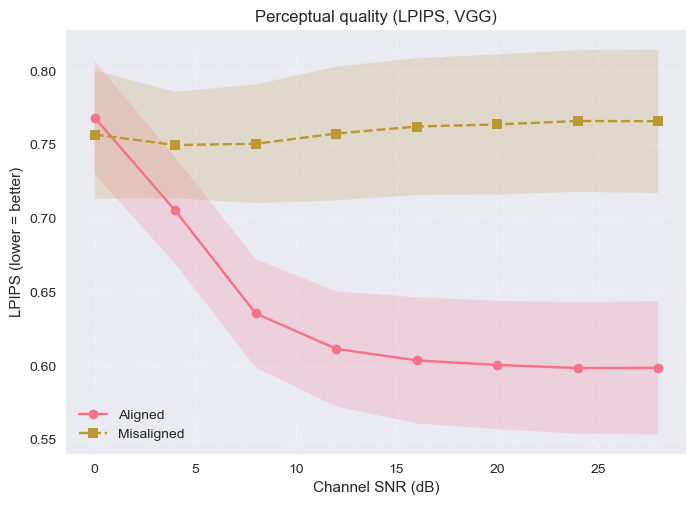

In [52]:
import torch
from kaira.metrics.image import LPIPS

_LPIPS_DEV = ("mps" if torch.backends.mps.is_available()
              else "cuda" if torch.cuda.is_available() else "cpu")
_lpips_metric = LPIPS(net_type="vgg", normalize=True).to(_LPIPS_DEV).eval()


def _to_tensor(img_uint8):
    """HxWx3 uint8 RGB -> 1x3xHxW float in [0,1] (normalize=True maps to [-1,1])."""
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1)
    return t.unsqueeze(0).float().div(255.0)


@torch.no_grad()
def summarize_lpips(cond):
    cd = ALIGN_DIR / cond
    snr_dirs = sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d) \
                       for d in cd.iterdir()
                       if d.is_dir() and SNR_DIR_RE.search(d.name)),
                      key=lambda t: t[0])
    out = []
    for snr, d in snr_dirs:
        vals = []
        for img_path in sorted(d.glob("*.png")):
            idx = int(img_path.with_suffix("").name.split("_")[1])
            o = originals.get(f"kodim{idx:02d}")
            if o is None:
                continue
            x = _to_tensor(load_rgb(img_path, WIDTH, HEIGHT)).to(_LPIPS_DEV)
            y = _to_tensor(o).to(_LPIPS_DEV)
            vals.append(float(_lpips_metric(x, y).mean().cpu()))
        a = np.asarray(vals)
        out.append((snr, a.mean(), a.std(), len(a)))
    return out


lpips_aligned = summarize_lpips("aligned")
lpips_misaligned = summarize_lpips("misaligned")
print("aligned:   ", [(s, round(m, 3)) for s, m, _, _ in lpips_aligned])
print("misaligned:", [(s, round(m, 3)) for s, m, _, _ in lpips_misaligned])

la_s, la_m, la_sd = _unpack(lpips_aligned)
lm_s, lm_m, lm_sd = _unpack(lpips_misaligned)

plt.plot(la_s, la_m, "o-", label="Aligned")
plt.fill_between(la_s, la_m + la_sd, la_m - la_sd, alpha=0.2)
plt.plot(lm_s, lm_m, "s--", label="Misaligned")
plt.fill_between(lm_s, lm_m + lm_sd, lm_m - lm_sd, alpha=0.2)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("LPIPS (lower = better)")
plt.title("Perceptual quality (LPIPS, VGG)")
plt.legend()
plt.show()

## Kaira metrics: PSNR (cross-check) & SSIM (all settings)

Recompute the fidelity metrics with Kaira's own implementations (`kaira.metrics.image`)
across every setting in this notebook (AWGN sweep, aligned, misaligned). Kaira's PSNR
should reproduce the manual numpy PSNR *exactly* (a validation of the pipeline); SSIM
adds a structural-similarity view (higher = better).

In [53]:
import torch
from kaira.metrics.image import PSNR as KairaPSNR, SSIM as KairaSSIM

_MDEV = ("mps" if torch.backends.mps.is_available()
         else "cuda" if torch.cuda.is_available() else "cpu")
_kaira_psnr = KairaPSNR(data_range=1.0).to(_MDEV).eval()
_kaira_ssim = KairaSSIM(data_range=1.0).to(_MDEV).eval()


def _img_tensor(img_uint8):
    """HxWx3 uint8 RGB -> 1x3xHxW float in [0,1] for the Kaira metrics."""
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1)
    return t.unsqueeze(0).float().div(255.0)


def _snr_dirs(base):
    return sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d)
                   for d in base.iterdir()
                   if d.is_dir() and SNR_DIR_RE.search(d.name)),
                  key=lambda t: t[0])


@torch.no_grad()
def summarize_metric(base, metric):
    """Mean/std of a Kaira image metric vs SNR over the snr_*dB subfolders of `base`."""
    out = []
    for snr, d in _snr_dirs(base):
        vals = []
        for img_path in sorted(d.glob("*.png")):
            idx = int(img_path.with_suffix("").name.split("_")[1])
            o = originals.get(f"kodim{idx:02d}")
            if o is None:                      # stray index w/o matching original
                continue
            x = _img_tensor(load_rgb(img_path, WIDTH, HEIGHT)).to(_MDEV)
            y = _img_tensor(o).to(_MDEV)
            vals.append(float(metric(x, y).mean().cpu()))
        a = np.asarray(vals)
        out.append((snr, a.mean(), a.std(), len(a)))
    return out


# Every experimental setting in this notebook.
SETTINGS = {
    "DJSCC (AWGN)": EXP_DIR,
    "Aligned":      ALIGN_DIR / "aligned",
    "Misaligned":   ALIGN_DIR / "misaligned",
}

psnr_kaira = {name: summarize_metric(base, _kaira_psnr) for name, base in SETTINGS.items()}
ssim_kaira = {name: summarize_metric(base, _kaira_ssim) for name, base in SETTINGS.items()}

# Validation: Kaira PSNR must reproduce the manual numpy PSNR from the AWGN sweep.
print("cross-check Kaira vs manual PSNR (AWGN sweep):")
for (s, mk, _, _), (s2, mn, _, _) in zip(psnr_kaira["DJSCC (AWGN)"], summary):
    print(f"  {s:>3} dB: kaira={mk:6.3f}  manual={mn:6.3f}  |delta|={abs(mk - mn):.4f}")

cross-check Kaira vs manual PSNR (AWGN sweep):
    0 dB: kaira=15.036  manual=15.036  |delta|=0.0000
    4 dB: kaira=17.876  manual=17.876  |delta|=0.0000
    8 dB: kaira=21.617  manual=21.617  |delta|=0.0000
   12 dB: kaira=24.515  manual=24.515  |delta|=0.0000
   16 dB: kaira=25.758  manual=25.758  |delta|=0.0000
   20 dB: kaira=26.361  manual=26.361  |delta|=0.0000
   24 dB: kaira=26.584  manual=26.584  |delta|=0.0000
   28 dB: kaira=26.613  manual=26.613  |delta|=0.0000


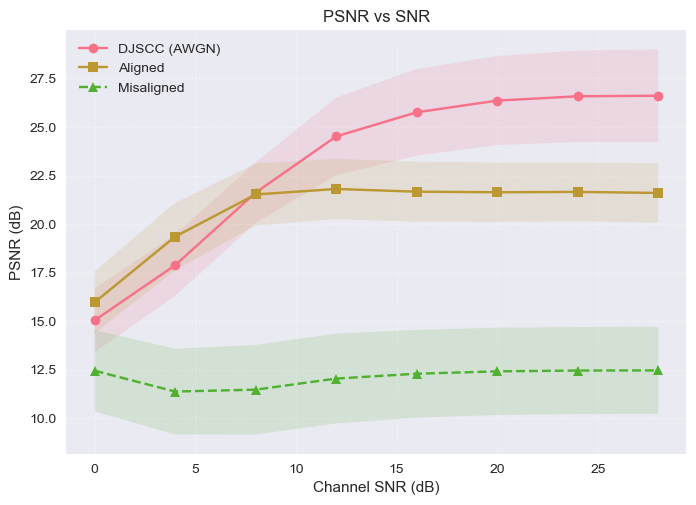

In [54]:
_STY = {"DJSCC (AWGN)": "o-", "Aligned": "s-", "Misaligned": "^--"}

for name, summ in psnr_kaira.items():
    s, m, sd = _unpack(summ)
    plt.plot(s, m, _STY[name], label=name)
    plt.fill_between(s, m + sd, m - sd, alpha=0.15)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("PSNR vs SNR")
plt.legend()
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_psnr_aligned_vs_misaligned.png", dpi=800, bbox_inches='tight')
plt.show()

In [55]:
# _STY = {"DJSCC (AWGN)": "o-", "Aligned": "s-", "Misaligned": "^--"}

# for name, summ in psnr_kaira.items():
#     s, m, sd = _unpack(summ)
#     plt.plot(s, m, _STY[name], label=name)
#     plt.fill_between(s, m + sd, m - sd, alpha=0.15)
# plt.grid(linestyle=":", alpha=0.5)
# plt.xlabel("Channel SNR (dB)")
# plt.ylabel("PSNR (dB)  [Kaira]")
# plt.title("PSNR vs SNR (Kaira) -- all settings")
# plt.legend()
# plt.show()

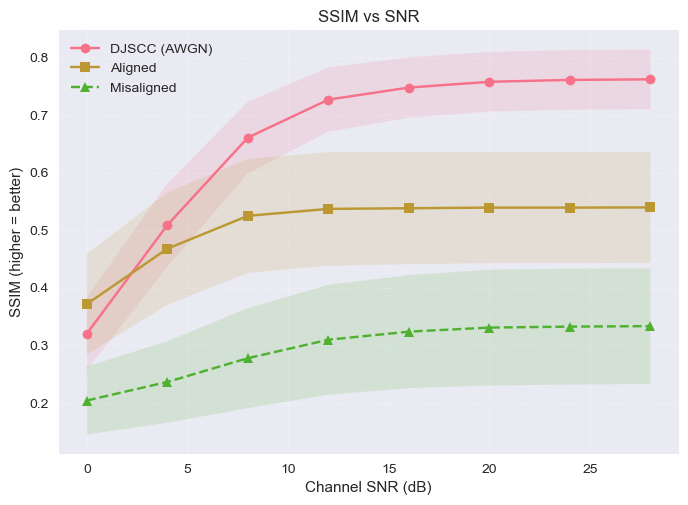

In [56]:
for name, summ in ssim_kaira.items():
    s, m, sd = _unpack(summ)
    plt.plot(s, m, _STY[name], label=name)
    plt.fill_between(s, m + sd, m - sd, alpha=0.15)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("SSIM (higher = better)")
plt.title("SSIM vs SNR")
plt.legend()
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_ssim_aligned_vs_misaligned.png", dpi=800, bbox_inches='tight')
plt.show()

In [57]:
# for name, summ in ssim_kaira.items():
#     s, m, sd = _unpack(summ)
#     plt.plot(s, m, _STY[name], label=name)
#     plt.fill_between(s, m + sd, m - sd, alpha=0.15)
# plt.grid(linestyle=":", alpha=0.5)
# plt.xlabel("Channel SNR (dB)")
# plt.ylabel("SSIM (higher = better)")
# plt.title("SSIM vs SNR (Kaira) -- all settings")
# plt.legend()
# plt.show()

## Conventional SSCC baseline (JPEG/JPEG2000 + LDPC + OFDM)

Same metrics as above (PSNR, SSIM, LPIPS vs SNR) plus visual inspection, but for
the classical separated source/channel coding baseline instead of DJSCC.
`results/conventional/snr_<SNR>dB/ldpc_n<N>_k<K>_mod<MOD>/` holds one run per
(SNR, LDPC rate, modulation order) combination, produced with `--exp-id-mode`
so every folder has a `manifest.csv` mapping `image_id` (0-based transmission
order) -> filename (`image_<id>.png`, or `image_<id>_fail.png` when the LDPC
decode or JPEG decompression failed and a placeholder was saved instead).
`image_id` 0 is the first image in the TX dataset folder (alphabetical), which
is the same Kodak set used above, so `image_id + 1 == kodimNN`.

Expect a much sharper "cliff" than DJSCC: below the LDPC's decoding threshold
for a given (rate, modulation), almost every image fails outright (placeholder
saved, `decode_ok=0`), while above threshold it recovers close to the JPEG
compression ceiling -- unlike DJSCC's graceful degradation.

In [58]:
CONV_DIR = RESULTS_DIR / "conventional"
COMBO_RE = re.compile(r"ldpc_n(\d+)_k(\d+)_mod(\d+)", re.IGNORECASE)
# image_<id>.png (decode ok) or image_<id>_fail.png (placeholder saved on decode failure)
CONV_IMG_RE = re.compile(r"image_(\d+)(_fail)?\.png$", re.IGNORECASE)
MOD_NAME = {1: "BPSK", 2: "QPSK", 4: "16QAM"}

# Flag: score decode failures (a black/placeholder reconstruction, saved with a
# "_fail" suffix in its filename) against a fixed theoretical worst-case value per
# metric, instead of computing the metric against the placeholder image itself.
# A bad-but-real reconstruction can score *worse* than a flat black image on some
# metrics, so scoring failures against the placeholder isn't guaranteed to be the
# true worst case -- flip this on to make every failure count as the worst possible
# score instead. Failure is detected purely from the "_fail" filename suffix.
USE_FAIL_FLOOR = True
FAIL_FLOOR = {"psnr": 0.0, "ssim": 0.0, "lpips": 1.0}  # PSNR/SSIM: 0 = worst; LPIPS: 1.0 = worst


def list_conventional_combos(conv_dir: Path):
    """{(ldpc_n, ldpc_k, mod_order): [(snr, run_dir), ...]}, each list sorted by snr."""
    combos = {}
    for snr_dir in sorted(conv_dir.iterdir()):
        if not snr_dir.is_dir():
            continue
        m_snr = SNR_DIR_RE.search(snr_dir.name)
        if not m_snr:
            continue
        snr = int(m_snr.group(1))
        for run_dir in sorted(snr_dir.iterdir()):
            if not run_dir.is_dir():
                continue
            m = COMBO_RE.search(run_dir.name)
            if not m:
                continue
            key = (int(m.group(1)), int(m.group(2)), int(m.group(3)))
            combos.setdefault(key, []).append((snr, run_dir))
    for runs in combos.values():
        runs.sort(key=lambda t: t[0])
    return combos


def combo_label(key):
    n, k, mod = key
    return f"LDPC {k}/{n} ({k / n:.2f}) - {MOD_NAME.get(mod, f'mod{mod}')}"


def iter_conventional_images(run_dir: Path):
    """Yield (recon_path, original_key, decode_ok) for one run dir.

    Reads the images directly from the folder: image_id and success are parsed
    from the filename (`image_<id>.png` -> ok, `image_<id>_fail.png` -> failure),
    so no manifest.csv is needed. image_id 0 maps to kodim01.
    """
    for img_path in sorted(run_dir.glob("*.png")):
        m = CONV_IMG_RE.search(img_path.name)
        if not m:
            continue
        img_id = int(m.group(1))
        decode_ok = m.group(2) is None  # no "_fail" suffix == decode succeeded
        yield img_path, f"kodim{img_id + 1:02d}", decode_ok


conv_combos = list_conventional_combos(CONV_DIR)
for key, runs in sorted(conv_combos.items()):
    print(f"{combo_label(key):<28} -> {[snr for snr, _ in runs]}")


LDPC 1152/2304 (0.50) - BPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1152/2304 (0.50) - QPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1152/2304 (0.50) - 16QAM -> [28]
LDPC 1728/2304 (0.75) - BPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1728/2304 (0.75) - QPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1728/2304 (0.75) - 16QAM -> [28]
LDPC 1920/2304 (0.83) - BPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1920/2304 (0.83) - QPSK -> [0, 4, 8, 12, 16, 20, 24, 28]
LDPC 1920/2304 (0.83) - 16QAM -> [28]


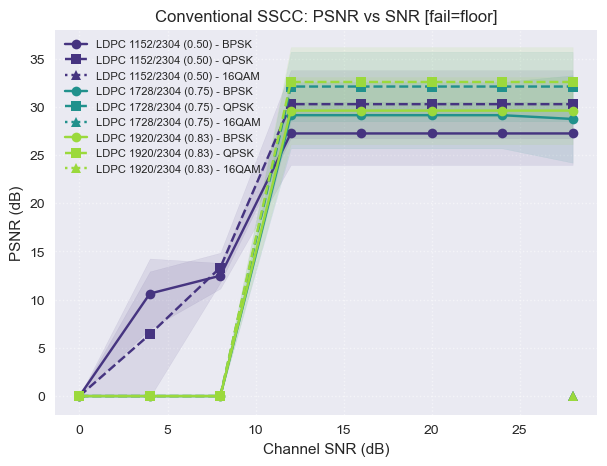

In [59]:
def summarize_conventional_metric(runs, metric_fn, fail_value=None):
    """Mean/std of a numpy metric_fn(recon_rgb, orig_rgb) -> float, vs SNR.

    fail_value: if not None, decode failures (decode_ok=0) are scored as this
    constant instead of computing metric_fn on the saved placeholder image.
    """
    out = []
    for snr, d in runs:
        vals = []
        for img_path, orig_key, decode_ok in iter_conventional_images(d):
            o = originals.get(orig_key)
            if o is None:
                continue
            if not decode_ok and fail_value is not None:
                vals.append(fail_value)
                continue
            if not img_path.exists():
                continue
            recon = load_rgb(img_path, WIDTH, HEIGHT)
            vals.append(metric_fn(recon, o))
        if vals:
            arr = np.asarray(vals)
            out.append((snr, float(arr.mean()), float(arr.std()), len(arr)))
    return out


conv_psnr = {key: summarize_conventional_metric(
                 runs, psnr, fail_value=FAIL_FLOOR["psnr"] if USE_FAIL_FLOOR else None)
             for key, runs in conv_combos.items()}

_MOD_LS = {1: "-", 2: "--", 4: ":"}
_MOD_MK = {1: "o", 2: "s", 4: "^"}
_conv_rates = sorted({k / n for n, k, _ in conv_combos})
_rate_color = dict(zip(_conv_rates, plt.cm.viridis(np.linspace(0.15, 0.85, len(_conv_rates)))))

plt.figure(figsize=(7, 5))
for key, summ in sorted(conv_psnr.items()):
    n, k, mod = key
    s, m, sd = _unpack(summ)
    c = _rate_color[k / n]
    plt.plot(s, m, marker=_MOD_MK.get(mod, "x"), linestyle=_MOD_LS.get(mod, "-"),
              color=c, label=combo_label(key))
    plt.fill_between(s, m + sd, m - sd, alpha=0.1, color=c)

plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("Conventional SSCC: PSNR vs SNR" + (" [fail=floor]" if USE_FAIL_FLOOR else ""))
plt.legend(fontsize=8)
plt.show()


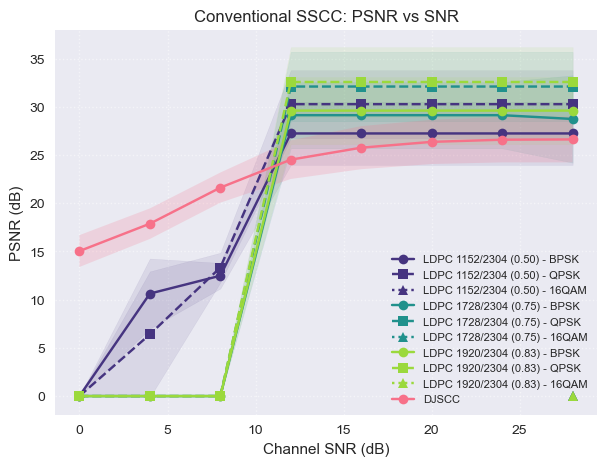

In [60]:
plt.figure(figsize=(7, 5))
for key, summ in sorted(conv_psnr.items()):
    n, k, mod = key
    s, m, sd = _unpack(summ)
    c = _rate_color[k / n]
    plt.plot(s, m, marker=_MOD_MK.get(mod, "x"), linestyle=_MOD_LS.get(mod, "-"),
              color=c, label=combo_label(key))
    plt.fill_between(s, m + sd, m - sd, alpha=0.1, color=c)

# DJSCC
plt.plot(snrs, means, "o-", label="DJSCC")
plt.fill_between(snrs, means+stds, means-stds, alpha=0.2)

plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("PSNR (dB)")
plt.title("Conventional SSCC: PSNR vs SNR")# + (" [fail=floor]" if USE_FAIL_FLOOR else ""))
plt.legend(fontsize=8, loc="lower right")
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_psnr-snr_djscc_vs_conventional.png", dpi=800, bbox_inches='tight')
plt.show()


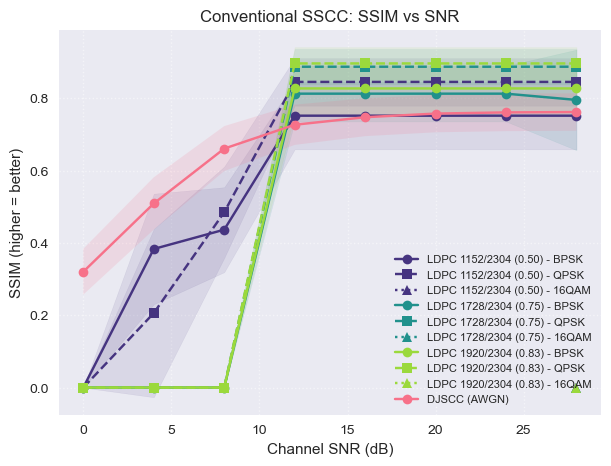

In [62]:
import torch
import torch
from kaira.metrics.image import SSIM as KairaSSIM, PSNR as KairaPSNR

_MDEV = ("mps" if torch.backends.mps.is_available()
         else "cuda" if torch.cuda.is_available() else "cpu")
_kaira_ssim = KairaSSIM(data_range=1.0).to(_MDEV).eval()


def _img_tensor(img_uint8):
    """HxWx3 uint8 RGB -> 1x3xHxW float in [0,1] for the Kaira metrics."""
    t = torch.from_numpy(np.ascontiguousarray(img_uint8)).permute(2, 0, 1)
    return t.unsqueeze(0).float().div(255.0)


def _snr_dirs(base):
    return sorted(((int(SNR_DIR_RE.search(d.name).group(1)), d)
                   for d in base.iterdir()
                   if d.is_dir() and SNR_DIR_RE.search(d.name)),
                  key=lambda t: t[0])


@torch.no_grad()
def summarize_conventional_torch(runs, metric, tensor_fn, device, fail_value=None):
    """Mean/std of a torch metric(x, y) -> tensor, vs SNR.

    fail_value: if not None, decode failures (decode_ok=0) are scored as this
    constant instead of running the metric on the saved placeholder image.
    """
    out = []
    for snr, d in runs:
        vals = []
        for img_path, orig_key, decode_ok in iter_conventional_images(d):
            o = originals.get(orig_key)
            if o is None:
                continue
            if not decode_ok and fail_value is not None:
                vals.append(fail_value)
                continue
            if not img_path.exists():
                continue
            x = tensor_fn(load_rgb(img_path, WIDTH, HEIGHT)).to(device)
            y = tensor_fn(o).to(device)
            vals.append(float(metric(x, y).mean().cpu()))
        if vals:
            arr = np.asarray(vals)
            out.append((snr, float(arr.mean()), float(arr.std()), len(arr)))
    return out

conv_ssim = {key: summarize_conventional_torch(
                 runs, _kaira_ssim, _img_tensor, _MDEV,
                 fail_value=FAIL_FLOOR["ssim"] if USE_FAIL_FLOOR else None)
             for key, runs in conv_combos.items()}

plt.figure(figsize=(7, 5))
for key, summ in sorted(conv_ssim.items()):
    n, k, mod = key
    s, m, sd = _unpack(summ)
    c = _rate_color[k / n]
    plt.plot(s, m, marker=_MOD_MK.get(mod, "x"), linestyle=_MOD_LS.get(mod, "-"),
              color=c, label=combo_label(key))
    plt.fill_between(s, m + sd, m - sd, alpha=0.1, color=c)

# DJSCC
name = "DJSCC (AWGN)"
summ = ssim_kaira[name]
s, m, sd = _unpack(summ)
plt.plot(s, m, _STY[name], label=name)
plt.fill_between(s, m + sd, m - sd, alpha=0.15)

plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("SSIM (higher = better)")
plt.title("Conventional SSCC: SSIM vs SNR")# + (" [fail=floor]" if USE_FAIL_FLOOR else ""))
plt.legend(fontsize=8, loc="lower right")
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_ssim-snr_djscc_vs_conventional.png", dpi=800, bbox_inches='tight')
plt.show()


In [24]:
conv_combos

{(2304,
  1152,
  1): [(0,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_0dB/ldpc_n2304_k1152_mod1')), (4,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_4dB/ldpc_n2304_k1152_mod1')), (8,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_8dB/ldpc_n2304_k1152_mod1')), (12,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_12dB/ldpc_n2304_k1152_mod1')), (16,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_16dB/ldpc_n2304_k1152_mod1')), (20,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_20dB/ldpc_n2304_k1152_mod1')), (24,
   PosixPath('/Users/marcellobullo/research/FINAL/github/djscc-playground/results/conventional/snr_24dB/ldpc_n2304_k1152_mod1')), (28,
   PosixPath('/Users/marcellobull

In [23]:
conv_ssim

{(2304, 1152, 1): [(0, 0.0, 0.0, 24),
  (4, 0.3833652293930451, 0.15286468609612017, 24),
  (8, 0.43674334200719994, 0.11741939965892234, 24),
  (12, 0.752092016239961, 0.09310145033941407, 24),
  (16, 0.752092016239961, 0.09310145033941407, 24),
  (20, 0.752092016239961, 0.09310145033941407, 24),
  (24, 0.752092016239961, 0.09310145033941407, 24),
  (28, 0.752092016239961, 0.09310145033941407, 24)],
 (2304, 1152, 2): [(0, 0.0, 0.0, 24),
  (4, 0.20596283363799253, 0.23270290202091748, 24),
  (8, 0.48500978760421276, 0.1262796685894934, 24),
  (12, 0.8455210750301679, 0.06549036780564119, 24),
  (16, 0.8455210750301679, 0.06549036780564119, 24),
  (20, 0.8455210750301679, 0.06549036780564119, 24),
  (24, 0.8455210750301679, 0.06549036780564119, 24),
  (28, 0.8455210750301679, 0.06549036780564119, 24)],
 (2304, 1728, 1): [(0, 0.0, 0.0, 24),
  (4, 0.0, 0.0, 24),
  (8, 0.0, 0.0, 24),
  (12, 0.813007486363252, 0.07683014840344153, 24),
  (16, 0.813007486363252, 0.07683014840344153, 24),
  (

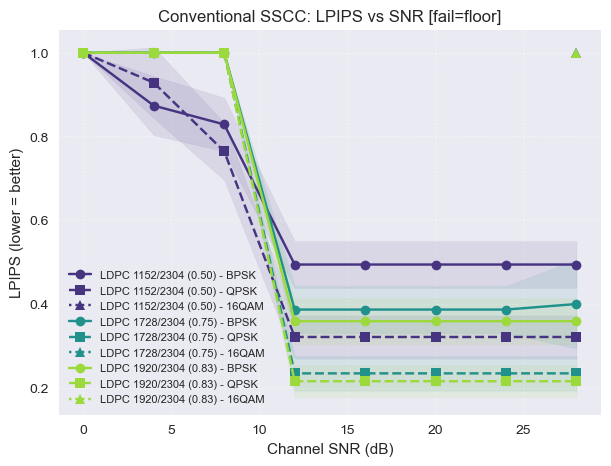

In [99]:
conv_lpips = {key: summarize_conventional_torch(
                  runs, _lpips_metric, _to_tensor, _LPIPS_DEV,
                  fail_value=FAIL_FLOOR["lpips"] if USE_FAIL_FLOOR else None)
              for key, runs in conv_combos.items()}

plt.figure(figsize=(7, 5))
for key, summ in sorted(conv_lpips.items()):
    n, k, mod = key
    s, m, sd = _unpack(summ)
    c = _rate_color[k / n]
    plt.plot(s, m, marker=_MOD_MK.get(mod, "x"), linestyle=_MOD_LS.get(mod, "-"),
              color=c, label=combo_label(key))
    plt.fill_between(s, m + sd, m - sd, alpha=0.1, color=c)
plt.grid(linestyle=":", alpha=0.5)
plt.xlabel("Channel SNR (dB)")
plt.ylabel("LPIPS (lower = better)")
plt.title("Conventional SSCC: LPIPS vs SNR" + (" [fail=floor]" if USE_FAIL_FLOOR else ""))
plt.legend(fontsize=8)
plt.show()


### Visual inspection

Same `kodim23` used throughout this notebook. First a single representative
condition (rate-1/2 LDPC, BPSK) across SNR, mirroring the single-condition
DJSCC grid above; then a multi-row grid comparing every fully-swept
(rate, modulation) combination across SNR, mirroring the aligned-vs-misaligned
grid in the Alignment section.

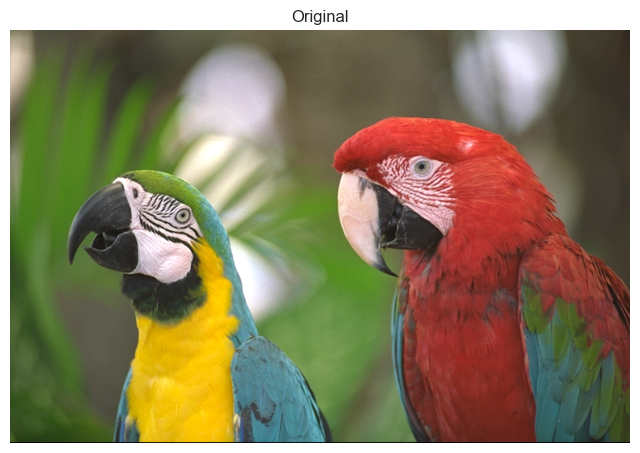

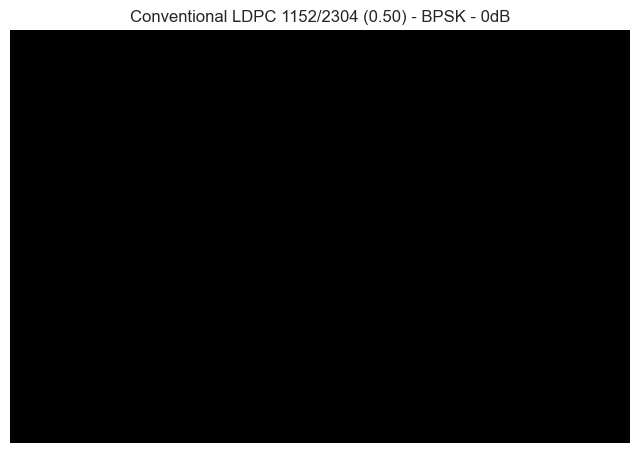

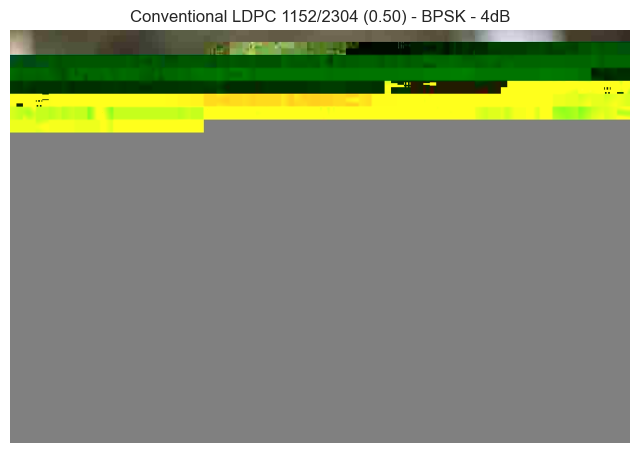

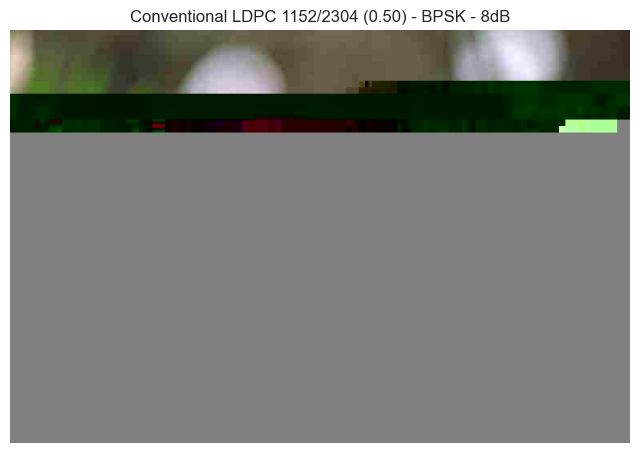

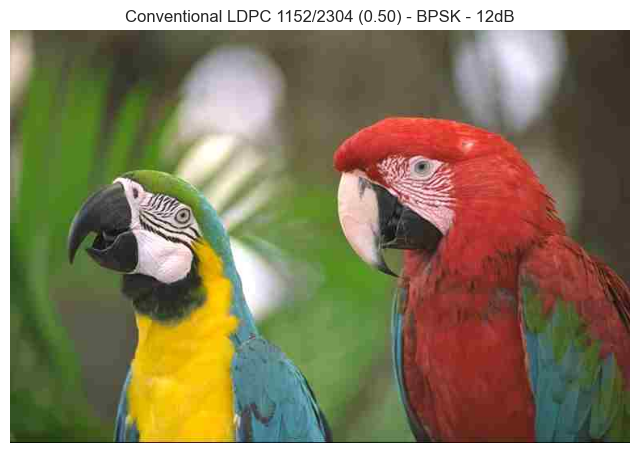

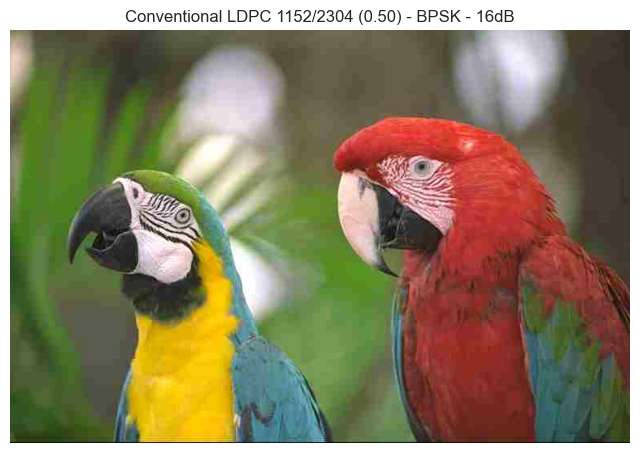

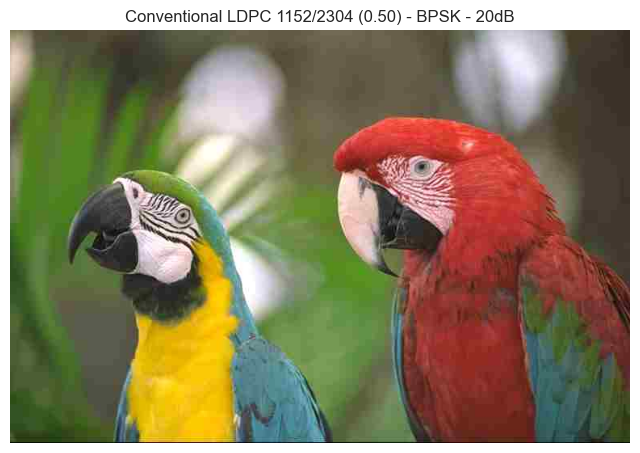

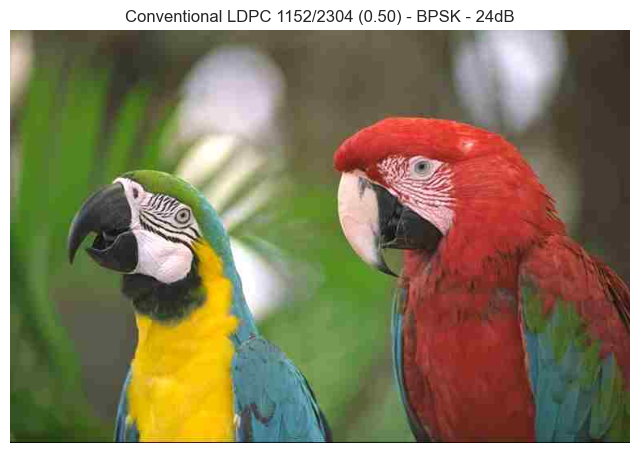

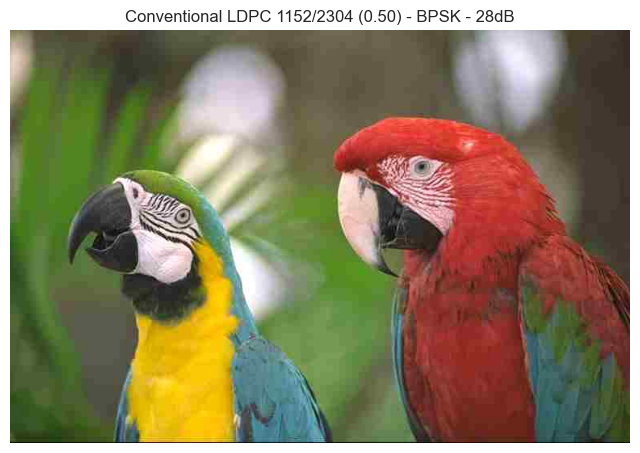

In [35]:
def conv_recon_for(run_dir: Path, kodim_idx: int):
    target = f"kodim{kodim_idx:02d}"
    for img_path, orig_key, decode_ok in iter_conventional_images(run_dir):
        if orig_key == target:
            return load_rgb(img_path, WIDTH, HEIGHT) if img_path.exists() else None
    return None


img_idx = 23  # kodimNN, same as the rest of the notebook

primary_key = (2304, 1152, 1)  # rate-1/2, BPSK -- matches the worked example above
img_orig = originals[f"kodim{img_idx:02}"]

plt.imshow(img_orig)
plt.title("Original")
plt.axis("off")
plt.show()

for snr, d in conv_combos[primary_key]:
    im = conv_recon_for(d, img_idx)
    plt.imshow(im if im is not None else np.zeros((HEIGHT, WIDTH, 3), dtype=np.uint8))
    plt.title(f"Conventional {combo_label(primary_key)} - {snr}dB")
    plt.axis("off")
    plt.show()


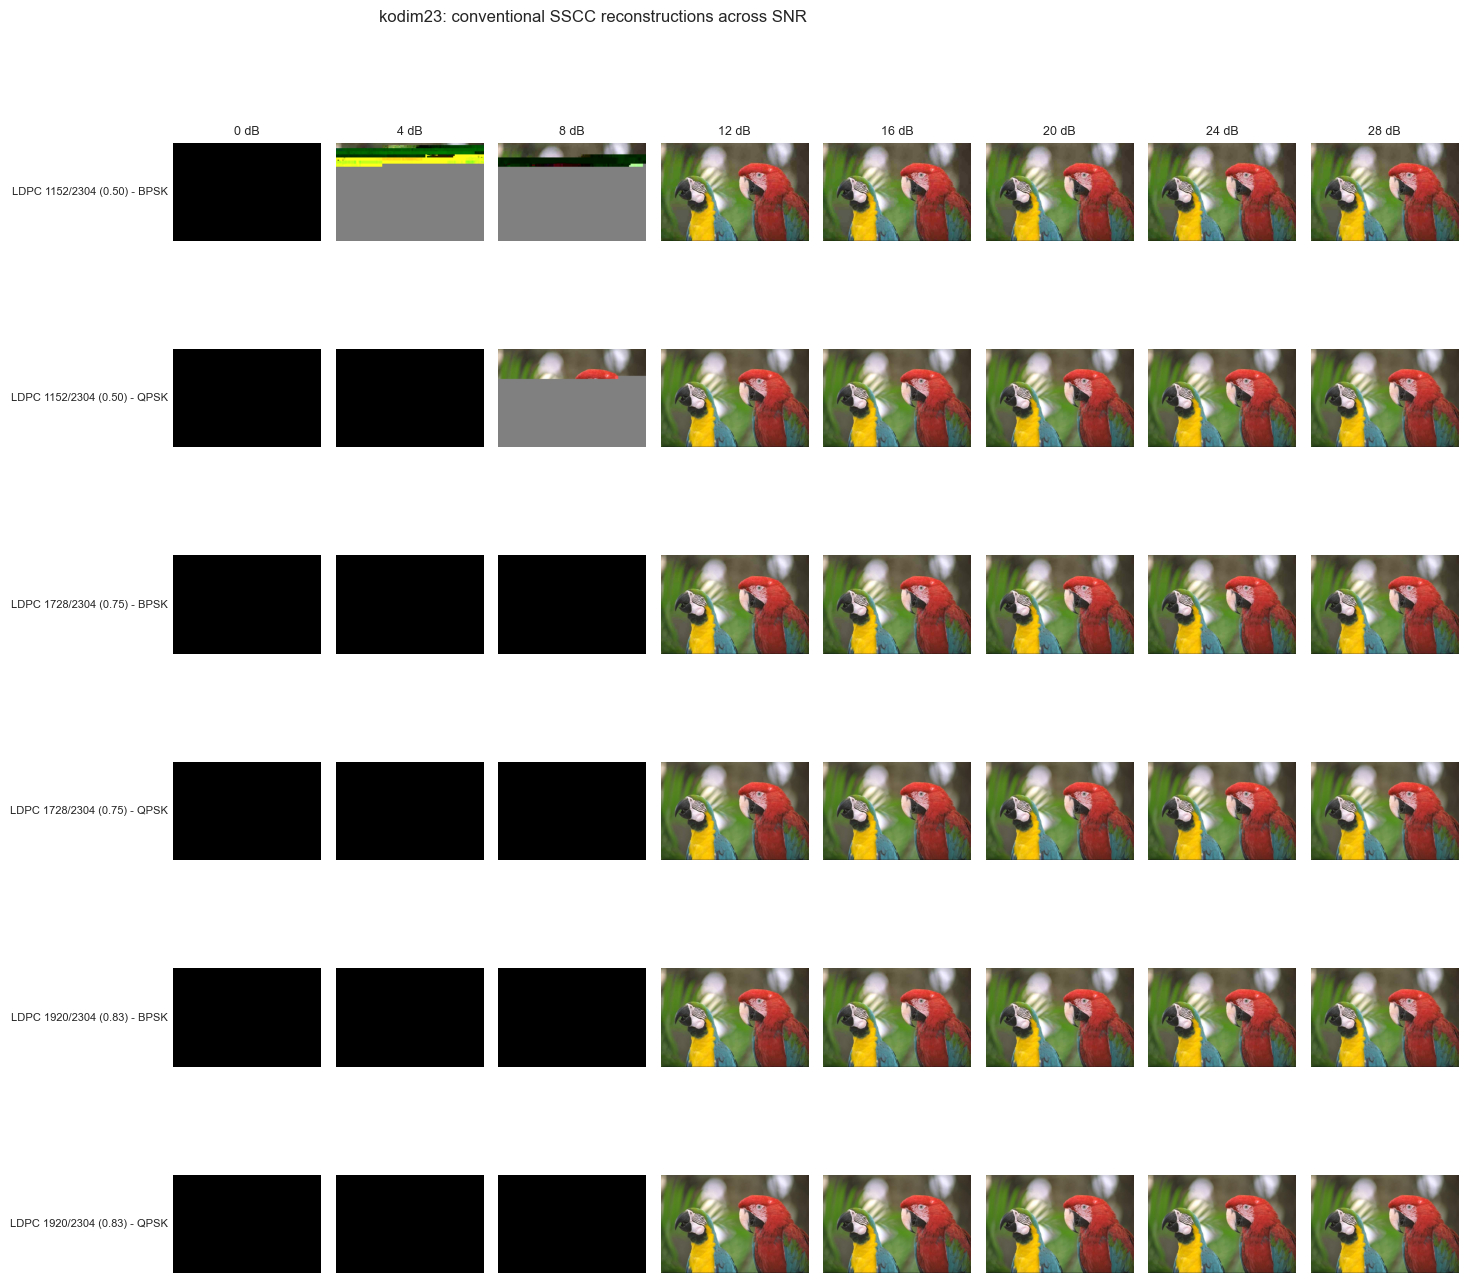

In [37]:
# Multi-row grid: one row per fully-swept (rate, modulation) combo, one column per SNR.
max_snr_count = max(len(runs) for runs in conv_combos.values())
grid_combos = [key for key, runs in sorted(conv_combos.items()) if len(runs) == max_snr_count]
common_snrs = [snr for snr, _ in conv_combos[grid_combos[0]]]

nrow, ncol = len(grid_combos), len(common_snrs)
fig, axs = plt.subplots(nrow, ncol, figsize=(2.2 * ncol, 2.3 * nrow))
if nrow == 1:
    axs = axs[None, :]

for i, key in enumerate(grid_combos):
    runs_by_snr = dict(conv_combos[key])
    for j, snr in enumerate(common_snrs):
        ax = axs[i, j]
        d = runs_by_snr.get(snr)
        im = conv_recon_for(d, img_idx) if d is not None else None
        if im is not None:
            ax.imshow(im)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i == 0:
            ax.set_title(f"{snr} dB", fontsize=9)
        if j == 0:
            ax.set_ylabel(combo_label(key), fontsize=8, rotation=0, ha="right", va="center")

fig.suptitle(f"kodim{img_idx:02d}: conventional SSCC reconstructions across SNR")
plt.tight_layout(rect=[0.16, 0, 1, 0.97])
plt.savefig(f"/Users/marcellobullo/Downloads/kodim{img_idx:02d}_conventional_recon_grid.png", dpi=800, bbox_inches='tight')
plt.show()


In [116]:
(1-(2/3)**(3)) / (1-2/3) - 1

1.1111111111111107

In [108]:
10/9

1.1111111111111112